# Compare gold forecasting models
Run any model notebook first. This notebook reads saved predictions and never retrains models.
Models are compared on the intersection of observed targets and common forecast origins.
The persistence baseline predicts the gold price observed at the origin.

In [1]:
from pathlib import Path
import os
# Limit CPU threads before importing optional numerical/model libraries.
os.environ.setdefault('TF_CPP_MIN_LOG_LEVEL', '2')
os.environ.setdefault('TF_NUM_INTRAOP_THREADS', '2')
os.environ.setdefault('TF_NUM_INTEROP_THREADS', '1')
import json
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display
from gold_common_utils import ROOT, load_config
# Load the shared experiment configuration.
cfg = load_config()
pd.set_option('display.max_columns', 20)
print('Project:', ROOT)
print('Target:', cfg['target_name'], '| horizons:', cfg['horizons'])

Project: /home/kosala/git-repos/exps/gold_forecasting
Target: Kitco Price (USD) | horizons: [1, 5, 20]


## 1. Load development results and check coverage

In [2]:
from gold_model_utils import compare_results
# Compare models only on the intersection of observable targets.
predictions, results, coverage = compare_results('cv')
display(coverage)
print('Models currently available:', predictions.model.unique().tolist())
display(results)

,total_predictions,observed_targets,common_predictions
model,,,
prophet,78,65,65
xgboost,78,65,65


Models currently available: ['prophet', 'xgboost', 'persistence', 'trailing_drift']


,model,fold,horizon,n,MAE,RMSE,MAPE,MASE,baseline_MAE,skill_vs_persistence
0,persistence,cv_1,1,5,9.580000,12.063747,0.487317,0.995400,9.580000,0.000000
1,persistence,cv_1,5,5,19.620000,25.841014,1.010948,2.038597,19.620000,0.000000
2,persistence,cv_1,20,4,22.650000,29.598902,1.176421,2.353426,22.650000,0.000000
3,persistence,cv_2,1,5,11.254000,19.277148,0.553139,1.174332,11.254000,0.000000
4,persistence,cv_2,5,4,46.242500,57.192776,2.173655,4.825309,46.242500,0.000000
5,persistence,cv_2,20,6,76.023333,103.441276,3.348023,7.932877,76.023333,0.000000
6,persistence,cv_3,1,4,13.507500,14.585502,0.536802,1.384296,13.507500,0.000000
7,persistence,cv_3,5,4,26.272500,43.643025,0.987695,2.692498,26.272500,0.000000
8,persistence,cv_3,20,4,55.287500,64.433918,2.246226,5.666058,55.287500,0.000000
9,persistence,cv_4,1,4,26.072500,27.825768,0.939586,2.593314,26.072500,0.000000


## 2. Compare pooled errors and fold stability

horizon,1,5,20
model,,,
persistence,17.695238,54.079091,91.137273
prophet,113.604037,127.048800,137.090181
trailing_drift,17.033942,50.991331,72.452388
xgboost,18.911336,52.379709,89.083322


mean        std        min         max
model          horizon                                              
persistence    1         19.356800  11.510920   9.580000   36.370000
               5         54.481800  34.669667  19.620000   99.790000
               20        92.648667  63.983930  22.650000  187.180000
prophet        1        118.843152  83.931393  36.619167  258.734312
               5        130.778144  69.661783  35.385345  215.996715
               20       137.394878  68.071653  36.693062  226.704686
trailing_drift 1         18.654064  11.570886   9.335159   36.193558
               5         51.612589  28.969152  21.806111   92.534841
               20        72.485529  34.506903  22.714286  109.079445
xgboost        1         20.698820  12.955514  11.647045   42.082778
               5         53.346613  29.694644  18.592170   96.459434
               20        87.323101  38.326989  41.516066  120.875028

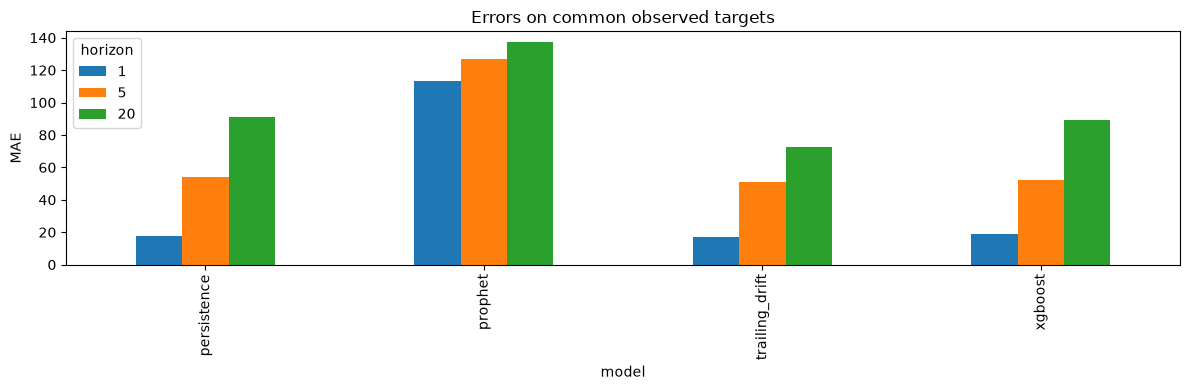

In [3]:
# Pooled MAE weights individual forecast errors equally within each horizon.
observed = predictions.dropna(subset=['actual', 'prediction']).copy()
observed['absolute_error'] = (observed.prediction - observed.actual).abs()
pooled = observed.groupby(['model', 'horizon']).absolute_error.mean().unstack('horizon')
display(pooled)
pooled.plot.bar(figsize=(12, 4), ylabel='MAE', title='Errors on common observed targets')
plt.tight_layout()
display(results.groupby(['model', 'horizon']).MAE.agg(['mean', 'std', 'min', 'max']))

## 3. Inspect residuals through time

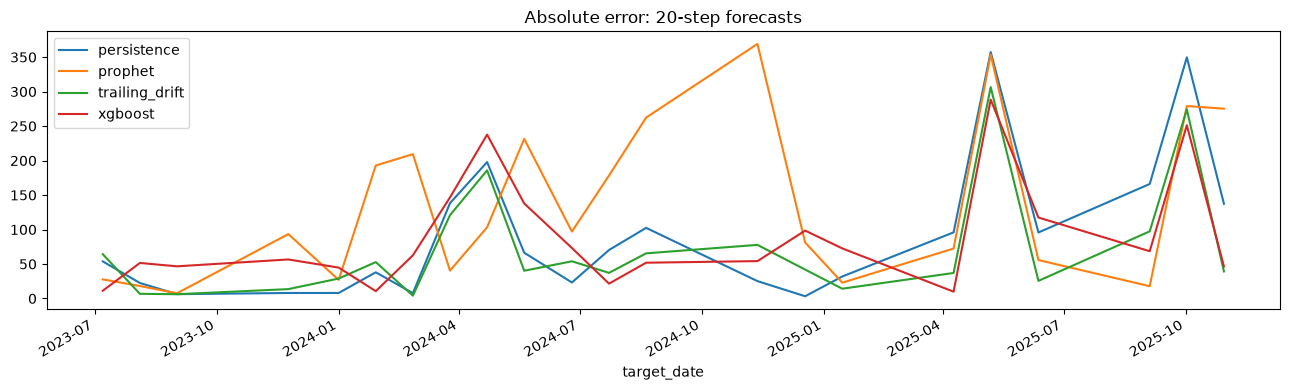

In [4]:
# Track the absolute error path through time, per model.
horizon = cfg['horizons'][-1]
fig, ax = plt.subplots(figsize=(13, 4))
for model, group in observed.loc[observed.horizon.eq(horizon)].groupby('model'):
    group.sort_values('target_date').plot(x='target_date', y='absolute_error', ax=ax, label=model)
ax.set_title(f'Absolute error: {horizon}-step forecasts')
plt.tight_layout()

## 4. Inspect external-feature selection
Inner scores show which feature group was selected without using the corresponding outer block.
Interpret importance as predictive association, not a causal explanation.

In [5]:
# Selection must use inner folds only; holdout results stay separate.
tables = []
for path in sorted((ROOT / 'artifacts').glob('*/inner_selection.csv')):
    table = pd.read_csv(path)
    table['model'] = path.parent.name
    tables.append(table)
if tables:
    selection = pd.concat(tables, ignore_index=True)
    selection['group'] = selection.params.map(lambda value: json.loads(value)['group'])
    display(selection.groupby(['model', 'group']).inner_MAE.agg(['mean', 'std', 'count']))

mean        std  count
model   group                                  
prophet external    91.918513  38.572467     10
        gold_only  159.621199  66.395229      5
xgboost external    48.431270  18.076692     10
        gold_only   49.212387  21.195865      5

## 5. Review final holdout results if available
Keep these separate from development results. Do not retune using this table.
The current package does not claim uncertainty intervals or verified real-time release vintages.

In [6]:
# Show each model's holdout results only after development is complete.
holdout_files = list((ROOT / 'artifacts').glob('*/holdout_predictions.csv'))
if holdout_files:
    holdout_predictions, holdout_results, holdout_coverage = compare_results('holdout')
    display(holdout_coverage)
    display(holdout_results)
else:
    print('No holdout results yet.')

No holdout results yet.
